<a href="https://colab.research.google.com/github/HusnulAmira/ADW/blob/main/Tugas_Pertemuan_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **SOAL**

1. Buatlah simulasi deret waktu (parameter yang digunakan bebas, tetapi berbeda dengan contoh yag sudah digunakan di atas) menggunakan seed 25xx, dimana xx adalah jumlah dua digit terakhir NIM anggota kelompok (misal NIM: 09 dan 28, maka seed yang digunakan 2537 . Lakukan pendugaan parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum:

Kelompok 1: ARIMA (0,0,1) dan ARIMA (2,2,2)

Kelompok 2: ARIMA (2,0,1) dan ARIMA (1,1,1)

Kelompok 3: ARIMA (1,0,1) dan ARIMA (1,1,2)

Kelompok 4: ARIMA (1,0,0) dan ARIMA (2,2,1)

Kelompok 5: ARIMA (2,0,0) dan ARIMA (2,1,1)

Kelompok 6: ARIMA (1,0,2) dan ARIMA (1,2,1)

Kelompok 7: ARIMA (0,0,2) dan ARIMA (1,2,2)

Kelompok 8: ARIMA (1,0,2) dan ARIMA (2,1,2)

Kelompok 9: ARIMA (2,0,2) dan ARIMA (1,2,1)

2. Ulangi langkah no.1 sebanyak 30 ulangan. Hitunglah bias dan ragam dari penduga parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum yang diperoleh dari 30 ulangan tersebut. Dan buatlah boxplot untuk memvisualisasikan bias dan ragam tersebut. Interpretasikan boxpot yang diperoleh

# **Jawaban**

Kelompok 5 :
ARIMA (2,0,0) dan ARIMA (2,1,1)
dengan nim 94+59+38=191 jadi 2591

# **Nomor 1**

In [73]:
!pip install rpy2

In [74]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


**Tentukan parameter dan periksa stasioneritas**

In [75]:
%%R

phi1 <- 0.6
phi2 <- -0.2
n <- 300

kriteria1 <- abs(phi2) < 1
kriteria2 <- (phi2 + phi1) < 1
kriteria3 <- (phi2 - phi1) < 1

hasil_kriteria <- data.frame(
  Kriteria = c(
    "|phi2| < 1",
    "phi2 + phi1 < 1",
    "phi2 - phi1 < 1"
  ),
  Nilai = c(
    abs(phi2),
    phi2 + phi1,
    phi2 - phi1
  ),
  Memenuhi = c(
    kriteria1,
    kriteria2,
    kriteria3
  )
)

print(hasil_kriteria, row.names = FALSE)


        Kriteria Nilai Memenuhi
      |phi2| < 1   0.2     TRUE
 phi2 + phi1 < 1   0.4     TRUE
 phi2 - phi1 < 1  -0.8     TRUE


**Simulasi satu ulangan dengan seed 2591**

Jumlah pengamatan: 300 
Time Series:
Start = 1 
End = 10 
Frequency = 1 
 [1] -0.01020952  1.80000981  0.65847943  0.24765135  1.78591067  2.12313349
 [7]  1.15105559 -2.18948225 -2.50152471 -0.65888287
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-2.89669 -0.74379  0.06673  0.04030  0.83461  3.86714 


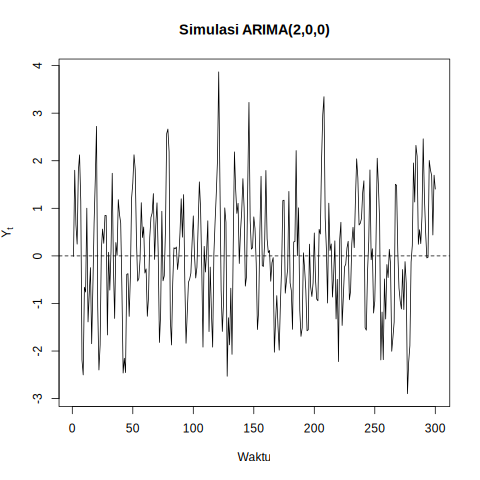

In [76]:
%%R

set.seed(2591)

ar2 <- arima.sim(
  list(
    order = c(2, 0, 0),
    ar = c(phi1, phi2)
  ),
  n = n
)

# Menampilkan data dan ringkasan
cat("Jumlah pengamatan:", length(ar2), "\n")
print(head(ar2, 10))
print(summary(ar2))

# Plot deret waktu
plot(
  ar2,
  type = "l",
  main = "Simulasi ARIMA(2,0,0)",
  xlab = "Waktu",
  ylab = expression(Y[t])
)

abline(h = 0, lty = 2)


**Pendugaan LS untuk satu ulangan**

In [77]:
%%R

# Pendugaan Least Squares (OLS)
hasil_LS <- ar(
  ar2,
  order.max = 2,
  AIC = FALSE,
  method = "ols"
)

print(hasil_LS)



Call:
ar(x = ar2, order.max = 2, method = "ols", AIC = FALSE)

Coefficients:
      1        2  
 0.6114  -0.1910  

Intercept: -0.004976 (0.05982) 

Order selected 2  sigma^2 estimated as  1.066


**Pendugaan MLE untuk satu ulangan**

In [78]:
%%R

# Pendugaan Maximum Likelihood
hasil_MLE <- ar(
  ar2,
  order.max = 2,
  AIC = FALSE,
  method = "mle"
)

print(hasil_MLE)


Call:
ar(x = ar2, order.max = 2, method = "mle", AIC = FALSE)

Coefficients:
      1        2  
 0.6101  -0.1915  

Order selected 2  sigma^2 estimated as  1.069


**Bandingkan hasil satu ulangan**

In [79]:
%%R

# Perbandingan dengan parameter asli
perbandingan_satu <- data.frame(
  Parameter = c("AR(1)", "AR(2)"),
  Parameter_Asli = c(phi1, phi2),
  LS = as.numeric(hasil_LS$ar),
  MLE = as.numeric(hasil_MLE$ar)
)

perbandingan_satu$Penyimpangan_LS <-
  perbandingan_satu$LS -
  perbandingan_satu$Parameter_Asli

perbandingan_satu$Penyimpangan_MLE <-
  perbandingan_satu$MLE -
  perbandingan_satu$Parameter_Asli

print(perbandingan_satu, row.names = FALSE)


 Parameter Parameter_Asli         LS        MLE Penyimpangan_LS
     AR(1)            0.6  0.6113579  0.6101009     0.011357938
     AR(2)           -0.2 -0.1910087 -0.1915421     0.008991292
 Penyimpangan_MLE
      0.010100924
      0.008457867


**Simulasi 30 ulangan dan estimasi LS serta MLE**

In [80]:
%%R

# ==================================================
# BAGIAN B: SIMULASI 30 ULANGAN
# ==================================================

set.seed(2026)

B <- 30

# Menyediakan tempat menyimpan hasil estimasi
estimasi_LS <- matrix(
  NA_real_,
  nrow = B,
  ncol = 2
)

estimasi_MLE <- matrix(
  NA_real_,
  nrow = B,
  ncol = 2
)

colnames(estimasi_LS) <- c("AR1", "AR2")
colnames(estimasi_MLE) <- c("AR1", "AR2")

# Simulasi dan pendugaan 30 kali
for (i in 1:B) {

  # Membangkitkan data baru
  x <- arima.sim(
    list(
      order = c(2, 0, 0),
      ar = c(phi1, phi2)
    ),
    n = n
  )

  # Pendugaan LS pada data yang sama
  fit_LS <- ar(
    x,
    order.max = 2,
    AIC = FALSE,
    method = "ols"
  )

  # Pendugaan MLE pada data yang sama
  fit_MLE <- ar(
    x,
    order.max = 2,
    AIC = FALSE,
    method = "mle"
  )

  # Menyimpan hasil pendugaan
  estimasi_LS[i, ] <- fit_LS$ar
  estimasi_MLE[i, ] <- fit_MLE$ar
}

cat("Jumlah ulangan:", B, "\n")

cat("\nLima hasil estimasi LS pertama:\n")
print(head(estimasi_LS, 5))

cat("\nLima hasil estimasi MLE pertama:\n")
print(head(estimasi_MLE, 5))


Jumlah ulangan: 30 

Lima hasil estimasi LS pertama:
           AR1        AR2
[1,] 0.5064860 -0.1046448
[2,] 0.5650469 -0.1632438
[3,] 0.6177791 -0.2494542
[4,] 0.6205657 -0.2042602
[5,] 0.5992501 -0.2731036

Lima hasil estimasi MLE pertama:
           AR1        AR2
[1,] 0.5068709 -0.1043825
[2,] 0.5696374 -0.1640284
[3,] 0.6221558 -0.2501829
[4,] 0.6174537 -0.2052887
[5,] 0.5987370 -0.2719846


In addition: Warning messages:
1: In arima0(x, order = c(i, 0L, 0L), include.mean = demean) :
  possible convergence problem: optim gave code = 1
2: In arima0(x, order = c(i, 0L, 0L), include.mean = demean) :
  possible convergence problem: optim gave code = 1
3: In arima0(x, order = c(i, 0L, 0L), include.mean = demean) :
  possible convergence problem: optim gave code = 1
4: In arima0(x, order = c(i, 0L, 0L), include.mean = demean) :
  possible convergence problem: optim gave code = 1
5: In arima0(x, order = c(i, 0L, 0L), include.mean = demean) :
  possible convergence problem: optim gave code = 1


**Hitung penyimpangan 30 ulangan**

In [81]:

%%R

# ==================================================
# PENYIMPANGAN ESTIMASI
# ==================================================

phi_asli <- c(phi1, phi2)

deviasi_LS <- sweep(
  estimasi_LS,
  2,
  phi_asli,
  FUN = "-"
)

deviasi_MLE <- sweep(
  estimasi_MLE,
  2,
  phi_asli,
  FUN = "-"
)

cat("Penyimpangan LS, lima ulangan pertama:\n")
print(head(deviasi_LS, 5))

cat("\nPenyimpangan MLE, lima ulangan pertama:\n")
print(head(deviasi_MLE, 5))


Penyimpangan LS, lima ulangan pertama:
               AR1          AR2
[1,] -0.0935140429  0.095355178
[2,] -0.0349530926  0.036756235
[3,]  0.0177790949 -0.049454248
[4,]  0.0205657126 -0.004260244
[5,] -0.0007498973 -0.073103608

Penyimpangan MLE, lima ulangan pertama:
              AR1          AR2
[1,] -0.093129124  0.095617516
[2,] -0.030362643  0.035971566
[3,]  0.022155841 -0.050182911
[4,]  0.017453730 -0.005288661
[5,] -0.001263025 -0.071984550


**Hitung bias dan ragam**

In [82]:
%%R

# ==================================================
# PERHITUNGAN BIAS DAN RAGAM
# ==================================================

# Bias = rata-rata estimasi - parameter asli
bias_LS <- colMeans(deviasi_LS)
bias_MLE <- colMeans(deviasi_MLE)

# Ragam empiris dari 30 estimasi
ragam_LS <- apply(estimasi_LS, 2, var)
ragam_MLE <- apply(estimasi_MLE, 2, var)

# Tabel hasil
hasil_akhir <- data.frame(
  Parameter = c("AR(1)", "AR(2)"),
  Nilai_Asli = phi_asli,
  Bias_LS = bias_LS,
  Bias_MLE = bias_MLE,
  Ragam_LS = ragam_LS,
  Ragam_MLE = ragam_MLE
)

print(hasil_akhir, row.names = FALSE)


 Parameter Nilai_Asli      Bias_LS      Bias_MLE   Ragam_LS   Ragam_MLE
     AR(1)        0.6 0.0001629325 -3.730467e-05 0.00385381 0.003844786
     AR(2)       -0.2 0.0254546546  2.561865e-02 0.02125362 0.021176141


**Buat boxplot penyimpangan**

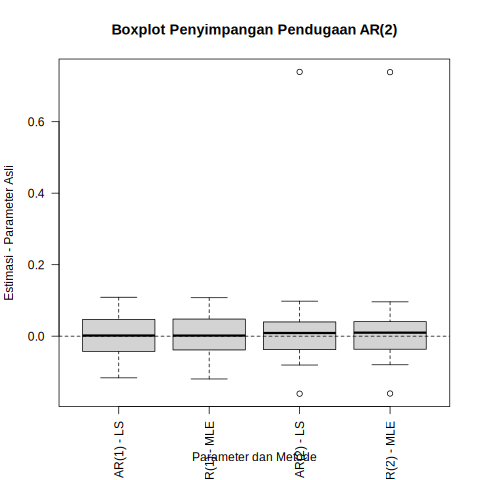

In [83]:
%%R

# ==================================================
# BOXPLOT PENYIMPANGAN LS DAN MLE
# ==================================================

box_data <- list(
  "AR(1) - LS" = deviasi_LS[, 1],
  "AR(1) - MLE" = deviasi_MLE[, 1],
  "AR(2) - LS" = deviasi_LS[, 2],
  "AR(2) - MLE" = deviasi_MLE[, 2]
)

boxplot(
  box_data,
  main = "Boxplot Penyimpangan Pendugaan AR(2)",
  xlab = "Parameter dan Metode",
  ylab = "Estimasi - Parameter Asli",
  las = 2
)

abline(h = 0, lty = 2)


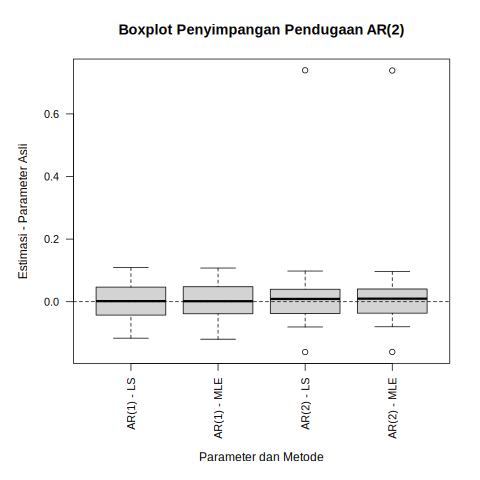

In [84]:
%%R

# ==================================================
# BOXPLOT PENYIMPANGAN LS DAN MLE
# ==================================================

box_data <- list(
  "AR(1) - LS" = deviasi_LS[, 1],
  "AR(1) - MLE" = deviasi_MLE[, 1],
  "AR(2) - LS" = deviasi_LS[, 2],
  "AR(2) - MLE" = deviasi_MLE[, 2]
)

par(mar = c(8, 5, 4, 2) + 0.1)

boxplot(
  box_data,
  main = "Boxplot Penyimpangan Pendugaan AR(2)",
  xlab = "",
  ylab = "Estimasi - Parameter Asli",
  las = 2,
  cex.axis = 0.9
)

mtext("Parameter dan Metode", side = 1, line = 6)
abline(h = 0, lty = 2)

par(mar = c(5, 4, 4, 2) + 0.1)


**Simpan seluruh hasil**

In [85]:

%%R

# Membuat tabel hasil 30 ulangan
hasil_30 <- data.frame(
  Ulangan = 1:B,
  LS_AR1 = estimasi_LS[, 1],
  LS_AR2 = estimasi_LS[, 2],
  MLE_AR1 = estimasi_MLE[, 1],
  MLE_AR2 = estimasi_MLE[, 2]
)

# Membuat tabel penyimpangan
penyimpangan_30 <- data.frame(
  Ulangan = 1:B,
  LS_AR1 = deviasi_LS[, 1],
  LS_AR2 = deviasi_LS[, 2],
  MLE_AR1 = deviasi_MLE[, 1],
  MLE_AR2 = deviasi_MLE[, 2]
)

# Menyimpan semua file di Google Colab
write.csv(
  hasil_30,
  "/content/hasil_estimasi_30_ulangan.csv",
  row.names = FALSE
)

write.csv(
  penyimpangan_30,
  "/content/hasil_penyimpangan_30_ulangan.csv",
  row.names = FALSE
)

write.csv(
  hasil_akhir,
  "/content/ringkasan_bias_ragam.csv",
  row.names = FALSE
)

write.csv(
  perbandingan_satu,
  "/content/perbandingan_satu_ulangan_seed2591.csv",
  row.names = FALSE
)

cat("Semua file berhasil disimpan di /content.\n")


Semua file berhasil disimpan di /content.
